<a href="https://colab.research.google.com/github/jovanfranco/usdmxn-volatilidad/blob/main/clase3_graficas_distribucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_13801/3272159148.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download("MXN=X", start="2022-01-01", progress=False)


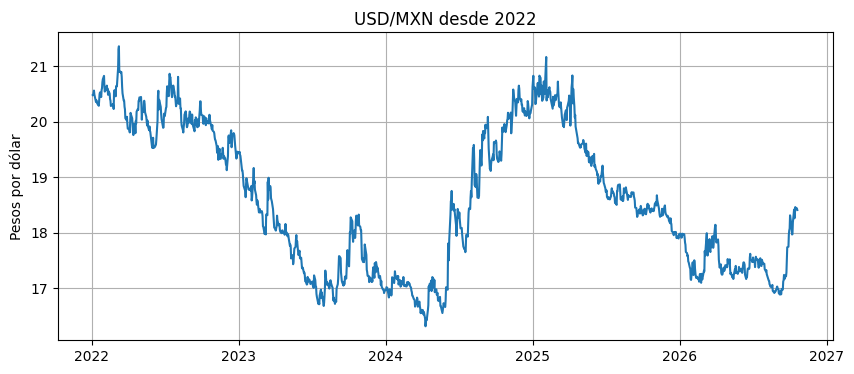

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

datos = yf.download("MXN=X", start="2022-01-01", progress=False)
cierre = datos["Close"].squeeze()

plt.figure(figsize=(10, 4))
plt.plot(cierre)
plt.title("USD/MXN desde 2022")
plt.ylabel("Pesos por dólar")
plt.grid(True)
plt.show()

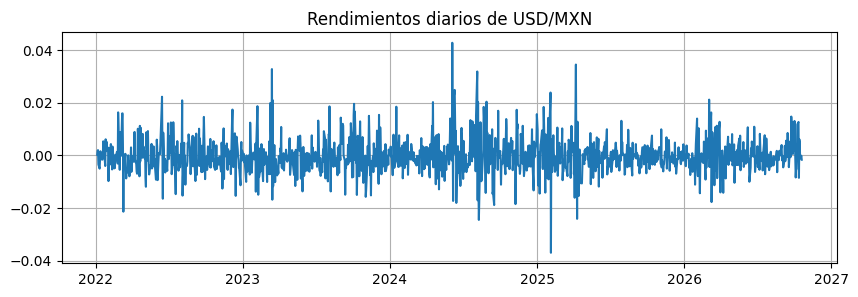

In [2]:
rend = cierre.pct_change().dropna()

plt.figure(figsize=(10, 3))
plt.plot(rend)
plt.title("Rendimientos diarios de USD/MXN")
plt.grid(True)
plt.show()

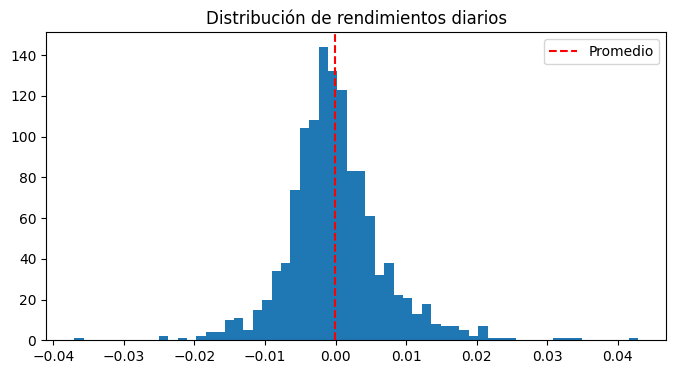

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(rend, bins=60)
plt.axvline(rend.mean(), color="red", linestyle="--", label="Promedio")
plt.title("Distribución de rendimientos diarios")
plt.legend()
plt.show()

In [4]:
dias_totales = len(rend)
dias_grandes = (rend.abs() > 0.01).sum()
print("Días totales:", dias_totales)
print("Días con movimiento mayor a 1%:", int(dias_grandes))
print("Probabilidad empírica:", round(float(dias_grandes / dias_totales), 3))

Días totales: 1246
Días con movimiento mayor a 1%: 150
Probabilidad empírica: 0.12


In [5]:
dias_totales = len(rend)
dias_grandes = (rend.abs() > 0.02).sum()
print("Días totales:", dias_totales)
print("Días con movimiento mayor a 1%:", int(dias_grandes))
print("Probabilidad empírica:", round(float(dias_grandes / dias_totales), 3))

Días totales: 1246
Días con movimiento mayor a 1%: 18
Probabilidad empírica: 0.014


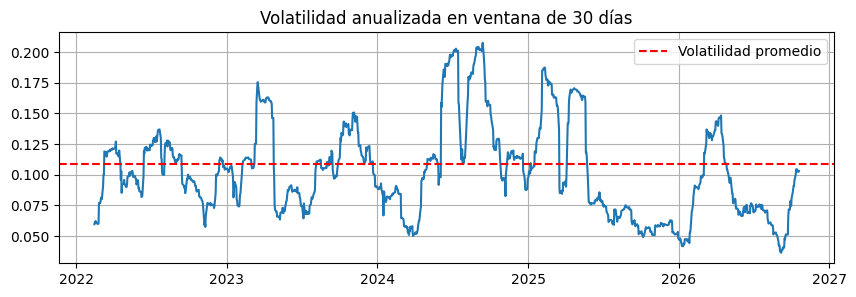

In [6]:
vol_movil = rend.rolling(30).std() * (252 ** 0.5)

plt.figure(figsize=(10, 3))
plt.plot(vol_movil)
plt.axhline(rend.std() * (252 ** 0.5), color="red", linestyle="--", label="Volatilidad promedio")
plt.title("Volatilidad anualizada en ventana de 30 días")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
print("Máxima:", round(float(vol_movil.max()), 3), "el", vol_movil.idxmax().date())
print("Mínima:", round(float(vol_movil.min()), 3), "el", vol_movil.idxmin().date())
print("Promedio:", round(float(vol_movil.mean()), 3))

Máxima: 0.208 el 2024-09-13
Mínima: 0.036 el 2026-09-07
Promedio: 0.103


Escala hoy: 0.97
Escala promedio: 1.11


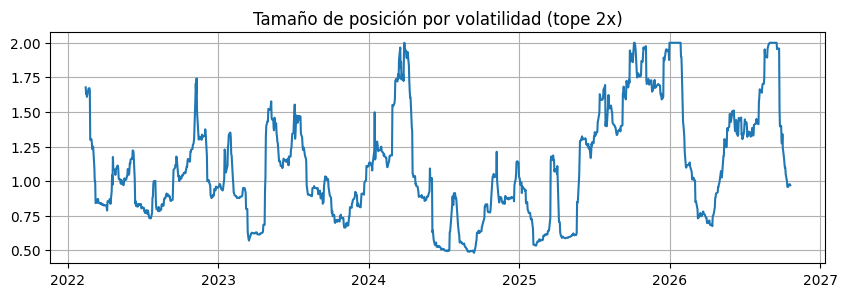

In [8]:
objetivo = 0.10
escala = (objetivo / vol_movil).clip(upper=2.0)

print("Escala hoy:", round(float(escala.iloc[-1]), 2))
print("Escala promedio:", round(float(escala.mean()), 2))

plt.figure(figsize=(10, 3))
plt.plot(escala)
plt.title("Tamaño de posición por volatilidad (tope 2x)")
plt.grid(True)
plt.show()

In [9]:
en_tope = escala >= 2.0
grupo = (en_tope != en_tope.shift()).cumsum()

for _, bloque in escala[en_tope].groupby(grupo[en_tope]):
    if len(bloque) >= 5:
        print(bloque.index[0].date(), "a", bloque.index[-1].date(), "|", len(bloque), "días")

2025-12-31 a 2026-01-27 | 19 días
2026-08-31 a 2026-09-17 | 14 días


In [10]:
print(en_tope.groupby(en_tope.index.year).sum())

Date
2022     0
2023     0
2024     1
2025     3
2026    32
Name: MXN=X, dtype: int64


In [11]:
tramo = vol_movil["2025-12-31":"2026-01-27"]
print("Mínima:", round(float(tramo.min()), 3), "| Máxima:", round(float(tramo.max()), 3))

Mínima: 0.042 | Máxima: 0.048


In [12]:
escala_real = escala.shift(1)
rend_vt = (escala_real * rend).dropna()

In [13]:
rend_comp = rend.loc[rend_vt.index]

for nombre, serie in [("Sin escalar", rend_comp), ("Con escala", rend_vt)]:
    vol = float(serie.std() * (252 ** 0.5))
    ret = float(serie.mean() * 252)
    print(nombre, "| Vol:", round(vol, 3), "| Rend:", round(ret, 3), "| Ratio:", round(ret / vol, 2))

Sin escalar | Vol: 0.109 | Rend: -0.016 | Ratio: -0.15
Con escala | Vol: 0.111 | Rend: -0.01 | Ratio: -0.09


In [14]:
for nombre, serie in [("Sin escalar", rend_comp), ("Con escala", rend_vt)]:
    v = serie.rolling(30).std() * (252 ** 0.5)
    print(nombre, "| Mín:", round(float(v.min()), 3), "| Máx:", round(float(v.max()), 3), "| Desv. de la vol:", round(float(v.std()), 3))

Sin escalar | Mín: 0.036 | Máx: 0.208 | Desv. de la vol: 0.038
Con escala | Mín: 0.049 | Máx: 0.166 | Desv. de la vol: 0.025


In [15]:
print("Autocorrelación de rendimientos:", round(float(rend.autocorr(lag=1)), 3))
print("Autocorrelación de rendimientos absolutos:", round(float(rend.abs().autocorr(lag=1)), 3))

Autocorrelación de rendimientos: -0.04
Autocorrelación de rendimientos absolutos: 0.216
